# Trust-region mechanism ablation (one seed)

This notebook runs the four combinations of adaptive/fixed radius and filtered/always-accept updates. Change only `SEED` below to repeat the four-group comparison with another algorithm seed. The underlying price scenario remains fixed at seed 42 to match the original-NN warm start.

Run the cells in order. Completed groups are skipped on rerun. The fixed-radius + filtered group stops after 10 consecutive actual rejections and records this as a stopping reason, not convergence. The solve cell is expensive: each iteration makes 61 composite high-fidelity queries. With just one seed, the effect estimates are descriptive and the 95% across-seed confidence intervals are undefined.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, FileLink

from stackelberg.tr_ablation import run_single_seed, analyze

# Change this one value to run a different paired four-group experiment.
SEED = 42

WARM_START_CSV = Path("results/NN_solver_original_ablation_history_20260919-112230.csv")
OUTPUT_DIR = Path("results") / f"tr_ablation_seed_{SEED}"
MAX_ITERATIONS = 30
STEPS_WARM = 1000
TARGET_OBJECTIVE = None  # None derives a descriptive target from the four runs.

print(f"Seed: {SEED}; output: {OUTPUT_DIR}")

Seed: 42; output: results/tr_ablation_seed_42


## Run the four groups

Run this cell once. If a run is interrupted, rerun it to continue from the next incomplete group. Do not change `MAX_ITERATIONS`, `STEPS_WARM`, or the warm-start file within an existing output directory.

In [2]:
run_single_seed(
    seed=SEED,
    warm_start_csv=WARM_START_CSV,
    output_dir=OUTPUT_DIR,
    max_iterations=MAX_ITERATIONS,
    steps_warm=STEPS_WARM,
)

Running seed=42, group=adaptive_filter
Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Using global surrogate to solve initial point...
Initial surrogate solve used steps_init=0. Time taken to solve initial point 0.0684 seconds.
Iteration 0 | R=0.0500 
Building 60-point local designs for each of 5 followers (center + coordinate star + LHS) within R_tr=0.0500...
Fitting follower-local residual models wit

## Analyze saved runs

This cell reads the four saved results without rerunning the solver. `best_at_budget` uses all evaluated true candidates; `final_returned` is the objective at the algorithm's returned point. Improvement vs NN is the NN baseline minus the final returned objective, so positive values are better.

Analyzed 1 paired seeds in results/tr_ablation_seed_42


,seed,group,best_at_budget,final_returned,auc_normalized,queries_to_target,elapsed_seconds,iterations,stop_reason,queries_used,would_reject_rate,actual_reject_rate,mean_candidate_surrogate_error,final_radius,nn_external_baseline
0,42,adaptive_filter,-99.786535,-99.786535,-99.461279,1098.0,13088.697869,26,converged,1586,0.653846,0.653846,0.388928,0.000094,-98.432043
1,42,adaptive_always_accept,-99.228773,-97.320985,-99.161501,NaN,14887.127971,30,max_iterations,1830,0.466667,0.000000,0.571474,0.013688,-98.432043
2,42,fixed_filter,-98.831881,-98.831881,-98.811999,NaN,5695.128119,12,consecutive_rejection_limit,732,0.833333,0.833333,1.166675,0.050000,-98.432043
3,42,fixed_always_accept,-99.005456,-98.895358,-98.907466,NaN,14659.794222,30,max_iterations,1830,0.433333,0.000000,0.566704,0.050000,-98.432043


,metric,effect,n,mean,ci_low,ci_high
0,best_at_budget,adaptive_benefit,1,0.588986,NaN,NaN
1,best_at_budget,filter_benefit,1,0.192093,NaN,NaN
2,best_at_budget,interaction,1,-0.731337,NaN,NaN
3,auc_normalized,adaptive_benefit,1,0.451657,NaN,NaN
4,auc_normalized,filter_benefit,1,0.102155,NaN,NaN
5,auc_normalized,interaction,1,-0.395244,NaN,NaN
6,final_returned,adaptive_benefit,1,-0.309859,NaN,NaN
7,final_returned,filter_benefit,1,1.201037,NaN,NaN
8,final_returned,interaction,1,-2.529027,NaN,NaN


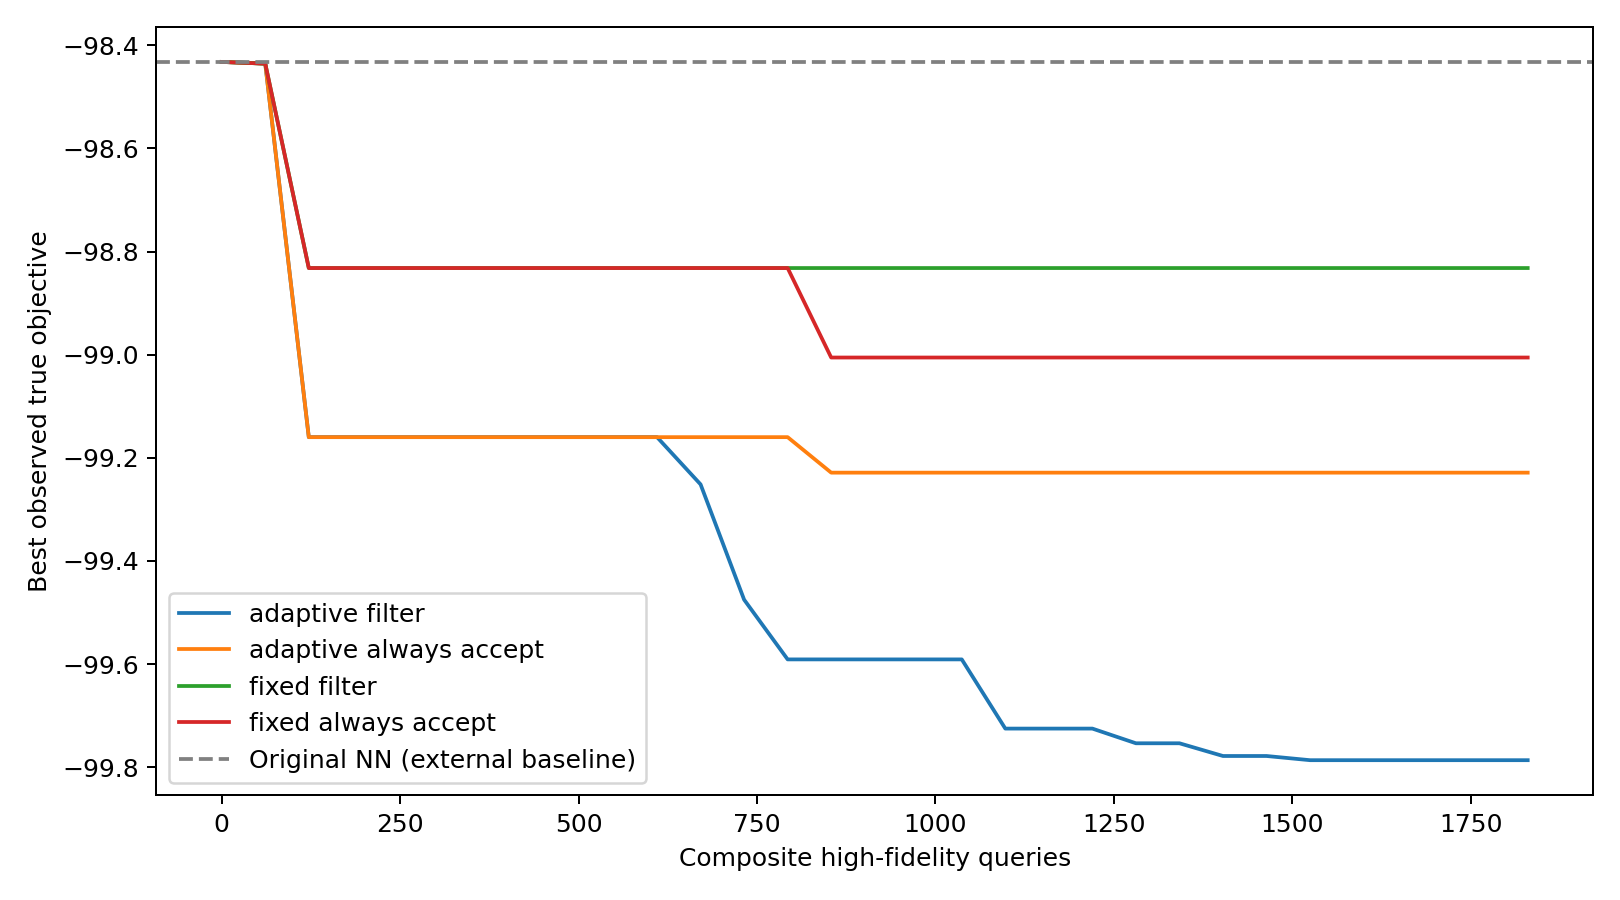

In [3]:
from IPython.display import FileLink

analyze(OUTPUT_DIR, MAX_ITERATIONS, target=TARGET_OBJECTIVE)

metrics = pd.read_csv(OUTPUT_DIR / "metrics.csv")
effects = pd.read_csv(OUTPUT_DIR / "paired_effects.csv")
metrics_display = metrics.assign(
    improvement_vs_nn=metrics['nn_external_baseline'] - metrics['final_returned']
).rename(columns={
    'best_at_budget': 'Best observed F ↓',
    'final_returned': 'Final solution F ↓',
    'improvement_vs_nn': 'Improvement vs NN ↑',
})
display(metrics_display)
display(effects)
display(FileLink(str(OUTPUT_DIR / "budget_curves.pdf")))